In [10]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(r"C:\Users\2024\Desktop\New folder\Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


mean -> (k=5)

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 55.296296               49.518519
1                 86.538462               82.128205
2                 25.727273               79.363636
3                 88.200000               17.114286
4                 26.304348               20.913043 

loyal customer

found 10 outlier customers !
     CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
132         133  Female   25                  72                      34   
184         185  Female   41                  99                      39   
192         193    Male   33                 113                       8   
193         194  Female   38                 113                      91   
194         195  Female   47                 120                      16   

     Cluster  
132        0  
184        3  
192        3  
193        1  
194        3   



c:\Users\2024\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


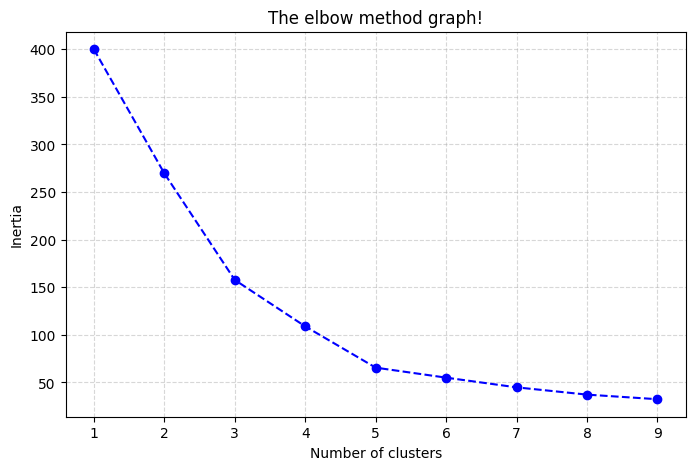

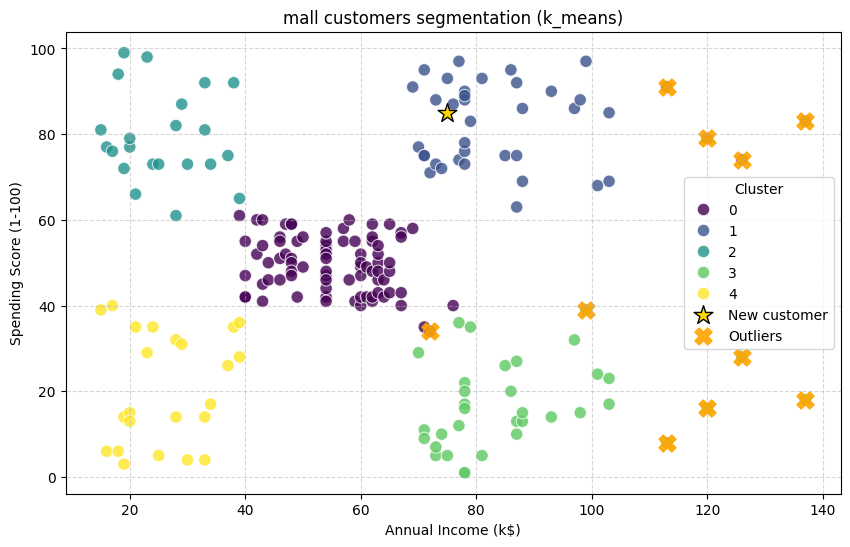

In [18]:
x = df[['Annual Income (k$)','Spending Score (1-100)']]

scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

inertias = []
for k in range(1,10):
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(x_scaled)
    inertias.append(kmeans.inertia_)
    
    
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k,random_state=42,n_init=10)
df['Cluster'] = kmeans.fit_predict(x_scaled)

print(f'mean -> (k={optimal_k})\n')

print(df.groupby('Cluster')[['Annual Income (k$)','Spending Score (1-100)']].mean(),'\n')

new_customer = [[75,85]]
new_customer_scaled = scaler.transform(new_customer)



predicted_cluster = kmeans.predict(new_customer_scaled)[0]

if predicted_cluster == 1:
    print('loyal customer\n')
    
elif predicted_cluster == 0:
    print('normal customer')    
    
########################################


distance = kmeans.transform(x_scaled)

min_distance = np.min(distance,axis=1)

threshold = np.percentile(min_distance,95)
outlier_mask = min_distance > threshold

outliers_df = df[outlier_mask]

print(f'found {len(outliers_df)} outlier customers !')

print(outliers_df.head(),'\n')


########################################


plt.figure(figsize=(8,5))
plt.plot(
    range(1,10),inertias,marker='o',color='b',linestyle='--')

plt.title('The elbow method graph!')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()


plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=80,
    alpha=0.8,
)

plt.scatter(
    new_customer[0][0],
    new_customer[0][1],
    color='gold',
    edgecolors='black',
    s=200,
    marker='*',
    label='New customer'    
)


plt.scatter(
    outliers_df['Annual Income (k$)'],
    outliers_df['Spending Score (1-100)'],
    color='orange',
    alpha=0.9,
    s=150,
    marker='X',
    label='Outliers'   
)    

plt.title('mall customers segmentation (k_means)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()
